In [1]:
#SHAP for Logistic Regression: which features does the model rely on? (RQ3)

In [2]:
import warnings
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

df = pd.read_csv("../data/oasis_longitudinal.csv")
df["label"] = (df["CDR"] > 0).astype(int)
df["Sex"] = (df["M/F"] == "M").astype(int)

y = df["label"]
groups = df["Subject ID"]

feature_sets = {
    "B (no MMSE)": ["Age", "Sex", "EDUC", "SES", "eTIV", "nWBV"],
    "A (with MMSE)": ["Age", "Sex", "EDUC", "SES", "eTIV", "nWBV", "MMSE"],
}

C:\Users\PMLS\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def shap_logreg(feats, seed=0):
    X = df[feats]
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    sv_all = np.zeros((len(df), len(feats)))   # SHAP values for every visit
    x_all = np.zeros((len(df), len(feats)))    # feature values, for the plot colours

    for train_idx, test_idx in cv.split(X, y, groups):
        # fill missing values and scale, learned from the training people only
        imputer = SimpleImputer(strategy="median").fit(X.iloc[train_idx])
        X_train_imp = imputer.transform(X.iloc[train_idx])
        X_test_imp = imputer.transform(X.iloc[test_idx])
        scaler = StandardScaler().fit(X_train_imp)
        X_train_t = scaler.transform(X_train_imp)
        X_test_t = scaler.transform(X_test_imp)

        lr = LogisticRegression(max_iter=1000).fit(X_train_t, y.iloc[train_idx])

        # explain only the people the model did NOT train on
        explainer = shap.LinearExplainer(lr, X_train_t)
        sv_all[test_idx] = explainer.shap_values(X_test_t)
        x_all[test_idx] = X_test_imp

    return sv_all, pd.DataFrame(x_all, columns=feats)

Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


B (no MMSE)
nWBV    0.833
Sex     0.713
EDUC    0.621
Age     0.469
eTIV    0.382
SES     0.235
dtype: float64



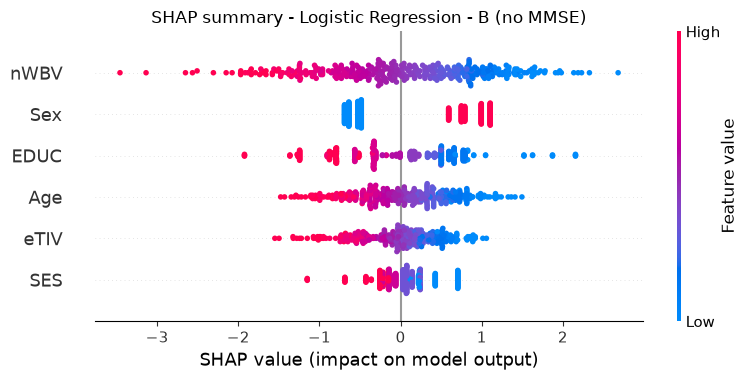

Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


A (with MMSE)
MMSE    2.105
Sex     0.764
nWBV    0.695
EDUC    0.606
Age     0.544
SES     0.419
eTIV    0.392
dtype: float64



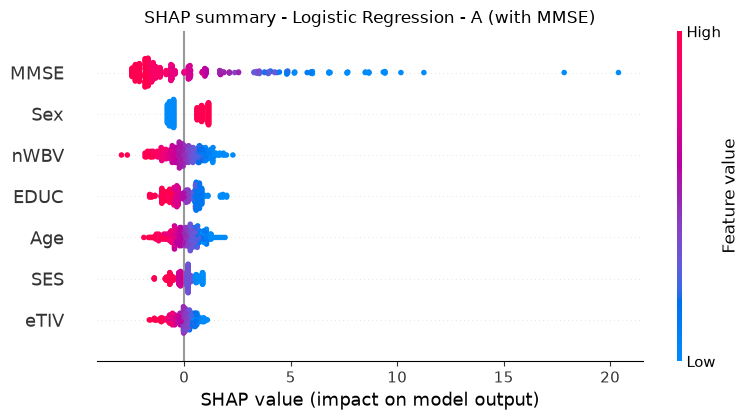

In [4]:
for exp_name, feats in feature_sets.items():
    sv, X_show = shap_logreg(feats)

    print(exp_name)
    importance = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
    print(importance.round(3))
    print()

    shap.summary_plot(sv, X_show, show=False)
    plt.title(f"SHAP summary - Logistic Regression - {exp_name}")
    plt.tight_layout()
    plt.savefig(f"../figures/shap_logreg_{exp_name[0]}.png", dpi=150)
    plt.show()

In [5]:
print(df[["Age", "nWBV", "eTIV", "EDUC", "SES"]].corr().round(2))
print()
print("Visits with dementia signs, by sex (1 = male):")
print(df.groupby("Sex")["label"].agg(["mean", "size"]).round(2))
print()
df["age_group"] = pd.cut(df["Age"], bins=[59, 70, 80, 90, 100])
print("Visits with dementia signs, by age group:")
print(df.groupby("age_group", observed=True)["label"].agg(["mean", "size"]).round(2))

       Age  nWBV  eTIV  EDUC   SES
Age   1.00 -0.52  0.04 -0.03 -0.05
nWBV -0.52  1.00 -0.21 -0.01  0.09
eTIV  0.04 -0.21  1.00  0.26 -0.26
EDUC -0.03 -0.01  0.26  1.00 -0.72
SES  -0.05  0.09 -0.26 -0.72  1.00

Visits with dementia signs, by sex (1 = male):
     mean  size
Sex            
0    0.33   213
1    0.60   160

Visits with dementia signs, by age group:
           mean  size
age_group            
(59, 70]   0.42    77
(70, 80]   0.47   173
(80, 90]   0.45   107
(90, 100]  0.31    16


In [6]:
from sklearn.ensemble import RandomForestClassifier

def shap_rf(feats, seed=0):
    X = df[feats]
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    sv_all = np.zeros((len(df), len(feats)))
    x_all = np.zeros((len(df), len(feats)))

    for train_idx, test_idx in cv.split(X, y, groups):
        imputer = SimpleImputer(strategy="median").fit(X.iloc[train_idx])
        X_train_imp = imputer.transform(X.iloc[train_idx])
        X_test_imp = imputer.transform(X.iloc[test_idx])

        rf = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=0)
        rf.fit(X_train_imp, y.iloc[train_idx])

        sv = shap.TreeExplainer(rf).shap_values(X_test_imp)
        if isinstance(sv, list):      # different shap versions return different shapes
            sv = sv[1]
        elif sv.ndim == 3:
            sv = sv[:, :, 1]

        sv_all[test_idx] = sv
        x_all[test_idx] = X_test_imp

    return sv_all, pd.DataFrame(x_all, columns=feats)

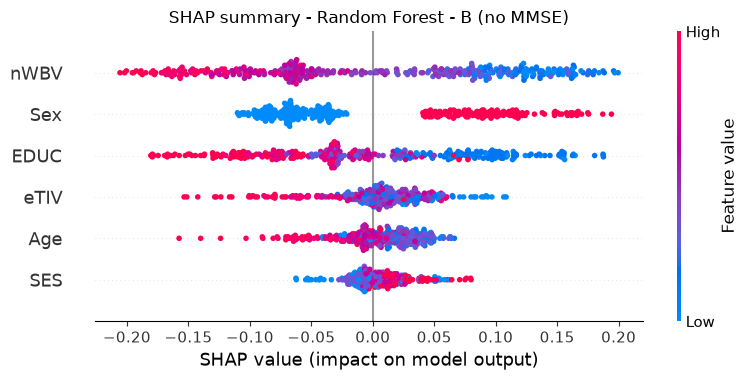

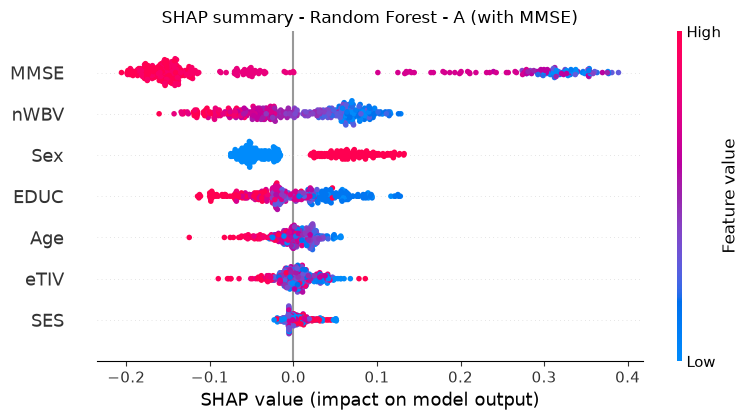

In [7]:
for exp_name, feats in feature_sets.items():
    sv, X_show = shap_rf(feats)
    shap.summary_plot(sv, X_show, show=False)
    plt.title(f"SHAP summary - Random Forest - {exp_name}")
    plt.tight_layout()
    plt.savefig(f"../figures/shap_rf_{exp_name[0]}.png", dpi=150)
    plt.show()

In [8]:
for exp_name, feats in feature_sets.items():
    lr_imp, rf_imp = [], []
    for seed in range(5):
        sv_lr, _ = shap_logreg(feats, seed)
        sv_rf, _ = shap_rf(feats, seed)
        lr_imp.append(np.abs(sv_lr).mean(axis=0))
        rf_imp.append(np.abs(sv_rf).mean(axis=0))

    table = pd.DataFrame({"LogReg": np.mean(lr_imp, axis=0),
                          "RandomForest": np.mean(rf_imp, axis=0)}, index=feats).round(3)
    table["LogReg rank"] = table["LogReg"].rank(ascending=False).astype(int)
    table["RF rank"] = table["RandomForest"].rank(ascending=False).astype(int)
    print(exp_name)
    print(table.sort_values("LogReg", ascending=False))
    print()

Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP val

B (no MMSE)
      LogReg  RandomForest  LogReg rank  RF rank
nWBV   0.839         0.097            1        1
Sex    0.704         0.077            2        2
EDUC   0.628         0.071            3        3
Age    0.473         0.025            4        5
eTIV   0.376         0.027            5        4
SES    0.220         0.016            6        6



Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 298 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=298 when initializing the masker.
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP val

A (with MMSE)
      LogReg  RandomForest  LogReg rank  RF rank
MMSE   2.133         0.188            1        1
Sex    0.749         0.053            2        3
nWBV   0.699         0.061            3        2
EDUC   0.604         0.041            4        4
Age    0.540         0.018            5        5
SES    0.396         0.009            6        7
eTIV   0.384         0.016            7        6



In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

Z = pd.DataFrame(StandardScaler().fit_transform(df[["Age", "nWBV"]]),
                 columns=["Age", "nWBV"])

m1 = LogisticRegression().fit(Z[["Age"]], y)
m2 = LogisticRegression().fit(Z[["Age", "nWBV"]], y)

print("Age alone:        Age coefficient =", m1.coef_[0][0].round(2))
print("Age + nWBV model: Age coefficient =", m2.coef_[0][0].round(2),
      "| nWBV coefficient =", m2.coef_[0][1].round(2))

Age alone:        Age coefficient = -0.04
Age + nWBV model: Age coefficient = -0.57 | nWBV coefficient = -1.02
